In [1]:
import warnings
from pathlib import Path

import plotly.express as px
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

DATA_DIR = Path("../data/raw/Airbnb")

# Airbnb Listings — Exploratory Data Analysis

Exploratory analysis of the Inside Airbnb snapshot used as the **revenue** data source for the property-pricing project (see the vault note `02 - Data Sources/Inside Airbnb.md`).

In [2]:
df_listings = pd.read_csv(DATA_DIR / "listings.csv", low_memory=False)
df_neighbourhoods = pd.read_csv(DATA_DIR / "neighbourhoods.csv")
pd.set_option("display.max_columns", None)

print(f"listings:       {df_listings.shape}")
print(f"neighbourhoods: {df_neighbourhoods.shape}")

listings:       (42354, 90)
neighbourhoods: (96, 2)


In [3]:
df_listings.head(3)

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,4917,https://www.airbnb.com/rooms/4917,20260614072545,2026-06-16,city scrape,Resort Condo Near Av. Paulista,"Comfortable 2 bedrooms (1 master suite), 2 bat...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,5618,https://www.airbnb.com/users/show/5618,1462506497915065828,https://www.airbnb.com/users/profile/146250649...,Alessandro,NaN,17,5,15,5,"Rome, Italy","Hi, I’m Alex, a Brazilian with Italian roots w...",NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/User-...,NaN,69,NaN,NaN,t,t,NaN,Vila Mariana,Vila Mariana,-23.57419,-46.63973,Entire condo,Entire home/apt,4,2.0,2 baths,2.0,3.0,"[""Free washer \u2013 In unit"", ""Ethernet conne...",$540.43,2026-07-21,2026-08-04,7566.00,540.43,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",5.0,1125.0,5.0,21.0,1125.0,1125.0,19.4,1125.0,NaN,t,2,19,32,57,2026-06-16,65,5,0,56,5,50,27022.0,2014-11-10,2026-05-07,4.85,4.91,4.65,4.94,4.94,4.97,4.67,NaN,NaN,1,1,0,0,0.46
1,54614,https://www.airbnb.com/rooms/54614,20260614072545,2026-06-16,city scrape,Nice area/Cozy flat/ Building rooftop pool,"Small, modern and charming flat. Cozy standard...",NaN,https://a0.muscache.com/pictures/31da1f7a-2d33...,256576,https://www.airbnb.com/users/show/256576,1462513920747223748,https://www.airbnb.com/users/profile/146251392...,Lílian,NaN,15,8,15,5,"São Paulo, Brazil","Frelancer journalist and audiovisual producer,...",NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/pictures/user/6896e...,NaN,1,NaN,NaN,t,t,NaN,Santa Cecilia,Se,-23.54153,-46.65362,Entire rental unit,Entire home/apt,3,1.0,1 bath,1.0,1.0,"[""Free washer \u2013 In unit"", ""Fire extinguis...",$289.04,2026-07-05,2026-08-04,8671.32,289.04,"{""quote"": {""taxes"": null, ""currency"": ""USD"", ""...",30.0,90.0,30.0,30.0,90.0,90.0,30.0,90.0,NaN,t,11,41,71,71,2026-06-16,209,1,1,71,0,60,17342.0,2015-12-14,2026-05-28,4.97,4.97,4.85,5.00,4.99,4.97,4.93,NaN,NaN,1,1,0,0,1.63
2,82935,https://www.airbnb.com/rooms/82935,20260614072545,2026-06-14,city scrape,Oscar Freire - Hospital das Clínicas e Nu Bank,I live in a 3-bedroom apartment in the most re...,NaN,https://a0.muscache.com/pictures/1cb69bb6-bb68...,451565,https://www.airbnb.com/users/show/451565,1462511917526407290,https://www.airbnb.com/users/profile/146251191...,Thaïs,NaN,15,2,15,2,"Sao Paulo, Brazil","My name is Thaïs, I love meeting people, 

## Dataset overview

In [4]:
print(f"Rows: {df_listings.shape[0]:,}  |  Columns: {df_listings.shape[1]}")
df_listings.dtypes.value_counts()

Rows: 42,354  |  Columns: 90


float64    37
object     29
int64      24
Name: count, dtype: int64

## Data quality: missing values

In [5]:
missing_pct = (df_listings.isna().mean() * 100).sort_values(ascending=False)
fully_empty = missing_pct[missing_pct == 100].index.tolist()
print(f"{len(fully_empty)} columns are 100% empty in this export:")
print(fully_empty)

13 columns are 100% empty in this export:
['host_total_listings_count', 'host_since', 'neighbourhood', 'host_verifications', 'calendar_updated', 'host_neighbourhood', 'host_thumbnail_url', 'neighborhood_overview', 'instant_bookable', 'license', 'host_response_time', 'host_response_rate', 'host_acceptance_rate']


In [6]:
df_listings = df_listings.drop(columns=fully_empty)
print(f"Dropped {len(fully_empty)} fully-empty columns. Shape is now {df_listings.shape}.")

Dropped 13 fully-empty columns. Shape is now (42354, 77).


## Drop out-of-scope columns

In [7]:
host_cols = [
    "host_id", "host_url", "host_profile_id", "host_profile_url", "host_name",
    "hosts_time_as_user_years", "hosts_time_as_user_months",
    "hosts_time_as_host_years", "hosts_time_as_host_months",
    "host_location", "host_about", "host_is_superhost", "host_picture_url",
    "host_listings_count", "host_has_profile_pic", "host_identity_verified",
    "calculated_host_listings_count_entire_homes",
    "calculated_host_listings_count_private_rooms", "calculated_host_listings_count_shared_rooms",
]  # calculated_host_listings_count is kept - used as a professional-host / saturation proxy in the neighbourhood analysis below
housekeeping_cols = [
     "scrape_id", "last_scraped", "source", "picture_url",
]
price_quote_cols = [
    "price_quote_checkin_date", "price_quote_checkout_date",
    "price_quote_total_price", "price_quote_price_per_night", "price_quote_raw",
]
redundant_nights_cols = [
    "minimum_minimum_nights", "maximum_minimum_nights",
    "minimum_maximum_nights", "maximum_maximum_nights",
]
redundant_availability_cols = [
    "availability_30", "availability_60", "availability_90",
    "has_availability", "availability_eoy", "calendar_last_scraped",
]
redundant_review_cols = [
    "number_of_reviews_ltm",
    "first_review", "last_review",
]

out_of_scope_cols = [
    c for c in (
        host_cols + housekeeping_cols + price_quote_cols
        + redundant_nights_cols + redundant_availability_cols + redundant_review_cols
    )
    if c in df_listings.columns
]

df_listings = df_listings.drop(columns=out_of_scope_cols)
print(f"Dropped {len(out_of_scope_cols)} out-of-scope columns "
      f"(host attributes, scrape/URL housekeeping, price-quote fields, "
      f"and redundant nights/availability/review variants).")
print(f"Shape is now {df_listings.shape}.")

Dropped 41 out-of-scope columns (host attributes, scrape/URL housekeeping, price-quote fields, and redundant nights/availability/review variants).
Shape is now (42354, 36).


In [8]:
df_listings.head(10)

,id,listing_url,name,description,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,minimum_nights,maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,availability_365,number_of_reviews,number_of_reviews_l30d,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,calculated_host_listings_count,reviews_per_month
0,4917,https://www.airbnb.com/rooms/4917,Resort Condo Near Av. Paulista,"Comfortable 2 bedrooms (1 master suite), 2 bat...",Vila Mariana,Vila Mariana,-23.574190,-46.639730,Entire condo,Entire home/apt,4,2.0,2 baths,2.0,3.0,"[""Free washer \u2013 In unit"", ""Ethernet conne...",$540.43,5.0,1125.0,19.4,1125.0,57,65,0,5,50,27022.0,4.85,4.91,4.65,4.94,4.94,4.97,4.67,1,0.46
1,54614,https://www.airbnb.com/rooms/54614,Nice area/Cozy flat/ Building rooftop pool,"Small, modern and charming flat. Cozy standard...",Santa Cecilia,Se,-23.541530,-46.653620,Entire rental unit,Entire home/apt,3,1.0,1 bath,1.0,1.0,"[""Free washer \u2013 In unit"", ""Fire extinguis...",$289.04,30.0,90.0,30.0,90.0,71,209,1,0,60,17342.0,4.97,4.97,4.85,5.00,4.99,4.97,4.93,1,1.63
2,82935,https://www.airbnb.com/rooms/82935,Oscar Freire - Hospital das Clínicas e Nu Bank,I live in a 3-bedroom apartment in the most re...,Jardim Paulista,Pinheiros,-23.556990,-46.674360,Private room in rental unit,Private room,1,1.0,1 private bath,NaN,1.0,"[""Free street parking"", ""Coffee maker: Nespres...",$309.00,1.0,1125.0,1.0,1125.0,326,107,0,13,54,16686.0,4.94,4.98,4.97,4.98,4.98,4.98,4.86,1,0.61
3,90394,https://www.airbnb.com/rooms/90394,Private Room in Vila Mariana Sao Paulo,"Located on the 9th floor, this cozy apartment ...",Vila Mariana,Vila Mariana,-23.591640,-46.648070,Private room in condo,Private room,1,2.0,2 shared baths,NaN,1.0,"[""Free washer \u2013 In unit"", ""Ethernet conne...",$225.00,1.0,1125.0,1.0,1125.0,331,341,7,22,108,24300.0,4.91,4.95,4.97,4.95,4.92,4.81,4.84,1,1.85
4,100549,https://www.airbnb.com/rooms/100549,"Cozy private ensuite, bath, balcony",Everything to be home away from home! The spac...,Morumbi,Butanta,-23.609030,-46.720770,Private room in home,Private room,2,NaN,1.5 baths,NaN,1.0,"[""Ethernet connection"", ""Fireplace guards"", ""C...",$243.71,7.0,30.0,7.0,30.0,348,33,0,0,0,0.0,4.84,4.67,4.70,4.91,4.94,4.67,4.61,8,0.18
5,128128,https://www.airbnb.com/rooms/128128,Quarto aconchegante no Morumbi,"The room is bright, airy, fully furnished, has...",Vila Andrade,Campo Limpo,-23.638313,-46.736019,Private room in rental unit,Private room,2,1.0,1 shared bath,2.0,1.0,"[""Hair dryer"", ""TV with standard cable"", ""Elev...",$205.50,2.0,30.0,2.0,30.0,345,33,1,6,36,7398.0,5.00,5.00,5.00,4.97,5.00,4.97,4.97,2,0.28
6,130606,https://www.airbnb.com/rooms/130606,Two-Bedroom Duplex Apartment superior,This is a beautiful Duplex in a luxurious buil...,Consolacao,Se,-23.556240,-46.659470,Entire rental unit,Entire home/apt,5,2.0,2 baths,2.0,4.0,"[""Hangers"", ""Air conditioning"", ""Washer"", ""Wif...","$1,082.00",2.0,1125.0,2.0,646.7,171,102,1,10,48,51936.0,4.83,4.91,4.86,4.96,4.91,4.99,4.65,4,0.56
7,156725,https://www.airbnb.com/rooms/156725,"Verde, silêncio, garagem, perto de tudo que é bom",A MAXIMUM OF 2 PEOPLE FOR WEEKEND STAYS AND ON...,Perdizes,Lapa,-23.539440,-46.683900,Private room in villa,Private room,2,1.5,1.5 baths,NaN,2.0,"[""Paid parking lot on premises \u2013 1 space""...",$225.00,1.0,7.0,1.0,7.0,179,78,0,6,30,6750.0,4.88,4.95,4.92,4.96,4.96,4.94,4.82,1,0.70
8,161994,https://www.airbnb.com/rooms/161994,Apto In São Paulo downtown Bela vista,NaN,Bela Vista,Se,-23.556310,-46.640920,Private room in rental unit,Private room,2,NaN,1.5 baths,NaN,1.0,"[""Body soap"", ""Dishes and silverware"", ""Extra ...",$472.43,3.0,730.0,3.0,730.0,365,0,0,0,0,0.0,NaN,NaN,NaN

## Geographic scope check

In [9]:
print("Unique neighbourhood_group_cleansed values:")
print(sorted(df_listings["neighbourhood_group_cleansed"].dropna().unique()))

print("\nTop 15 neighbourhood_cleansed by listing count:")
print(df_listings["neighbourhood_cleansed"].value_counts().head(15))

lat_min, lat_max = df_listings["latitude"].min(), df_listings["latitude"].max()
lon_min, lon_max = df_listings["longitude"].min(), df_listings["longitude"].max()
print(f"\nBounding box: lat [{lat_min:.3f}, {lat_max:.3f}], lon [{lon_min:.3f}, {lon_max:.3f}]")

Unique neighbourhood_group_cleansed values:
['Aricanduva-Formosa-Carrao', 'Butanta', 'Campo Limpo', 'Capela Do Socorro', 'Casa Verde-Limao-Cachoeirinha', 'Cidade Ademar', 'Cidade Tiradentes', 'Ermelino Matarazzo', 'Freguesia-Brasilandia', 'Guaianases', 'Ipiranga', 'Itaim Paulista', 'Itaquera', 'Jabaquara', 'Jacana-Tremembe', 'Lapa', 'M Boi Mirim', 'Mooca', 'Parelheiros', 'Penha', 'Perus-Anhanguera', 'Pinheiros', 'Pirituba-Jaragua', 'Santana-Tucuruvi', 'Santo Amaro', 'Sao Mateus', 'Sao Miguel', 'Sapopemba', 'Se', 'Vila Maria-Vila Guilherme', 'Vila Mariana', 'Vila Prudente']

Top 15 neighbourhood_cleansed by listing count:
neighbourhood_cleansed
Itaim Bibi         4382
Republica          3705
Jardim Paulista    3500
Moema              2857
Pinheiros          2838
Vila Mariana       2722
Bela Vista         2459
Perdizes           1979
Consolacao         1927
Santo Amaro        1862
Campo Belo         1404
Bras                845
Saude               810
Santa Cecilia       745
Liberdade   

## Price cleaning

In [10]:
def clean_price(series: pd.Series) -> pd.Series:
    return (
        series.astype(str)
        .str.replace(r"[\$,]", "", regex=True)
        .replace("nan", np.nan)
        .astype(float)
    )


df_listings["price_clean"] = clean_price(df_listings["price"])

print(df_listings["price_clean"].describe())
print(f"\nMissing price: {df_listings['price_clean'].isna().mean():.1%}")

count    41832.000000
mean       418.046308
std        817.571526
min         11.530000
25%        250.000000
50%        331.000000
75%        429.502500
max      57127.000000
Name: price_clean, dtype: float64

Missing price: 1.2%


In [11]:
df_listings = df_listings[df_listings["price_clean"].between(10, 5000)]

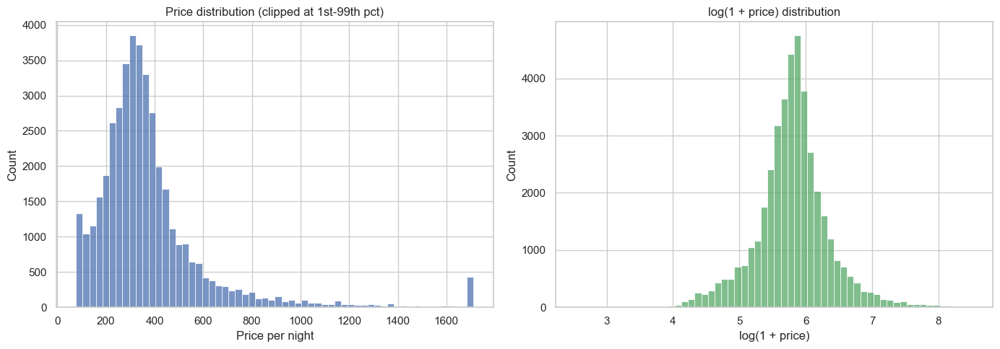

In [12]:
p1, p99 = df_listings["price_clean"].quantile([0.01, 0.99])
price_trimmed = df_listings["price_clean"].clip(lower=p1, upper=p99)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(price_trimmed, bins=60, ax=axes[0], color="#4C72B0")
axes[0].set_title("Price distribution (clipped at 1st-99th pct)")
axes[0].set_xlabel("Price per night")

sns.histplot(np.log1p(df_listings["price_clean"].dropna()), bins=60, ax=axes[1], color="#55A868")
axes[1].set_title("log(1 + price) distribution")
axes[1].set_xlabel("log(1 + price)")

plt.tight_layout()
plt.show()

In [13]:
df_listings.sort_values("price_clean", ascending=False).head(3)

,id,listing_url,name,description,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,minimum_nights,maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,availability_365,number_of_reviews,number_of_reviews_l30d,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,calculated_host_listings_count,reviews_per_month,price_clean
9283,828238195651488786,https://www.airbnb.com/rooms/828238195651488786,Club Suites - Duplo Sem Frigobar,"Digital Hotel, simple and practical for those ...",Campo Belo,Santo Amaro,-23.621949,-46.664387,Private room in home,Private room,2,1.0,1 private bath,1.0,1.0,"[""TV"", ""Wifi"", ""Exterior security cameras on p...","$5,000.00",1.0,1125.0,1.0,1125.0,174,1,0,0,0,0.0,2.00,1.00,3.00,2.00,3.00,5.0,2.00,3,0.03,5000.00
7293,660205635023217660,https://www.airbnb.com/rooms/660205635023217660,Mirante do Céu: vista linda em apto. completo!,The very high standard apartments of Mirante d...,Republica,Se,-23.542059,-46.635727,Entire rental unit,Entire home/apt,4,1.0,1 bath,1.0,2.0,"[""AC - split type ductless system"", ""Coffee ma...","$4,927.08",1.0,1125.0,7.3,1125.0,90,108,1,5,72,354750.0,4.92,4.94,4.95,4.92,4.96,4.6,4.81,4,2.25,4927.08
184,2207106,https://www.airbnb.com/rooms/2207106,RENT A HOUSE WORLD CUP IN BRAZIL,NaN,Santa Cecilia,Se,-23.522380,-46.650890,Entire home,Entire home/apt,1,1.0,1 bath,1.0,3.0,"[""Smoking allowed"", ""Pets allowed"", ""TV with s...","$4,908.00",1.0,1125.0,1.0,1125.0,365,1,0,0,0,0.0,5.00,5.00,5.00,5.00,5.00,5.0,4.00,1,0.01,4908.00


In [14]:
df_listings = df_listings[df_listings["number_of_reviews"] != 0].copy()
print(f"Shape now {df_listings.shape}.")

Shape now (36257, 37).


## Room type & property type

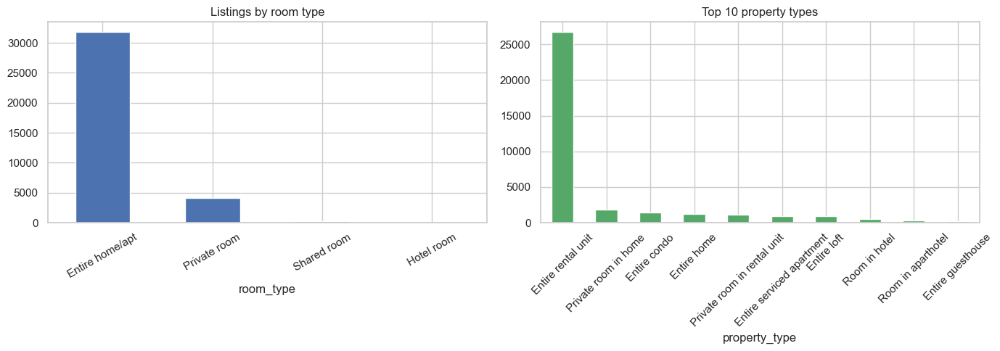

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_listings["room_type"].value_counts().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Listings by room type")
axes[0].tick_params(axis="x", rotation=30)

df_listings["property_type"].value_counts().head(10).plot(kind="bar", ax=axes[1], color="#55A868")
axes[1].set_title("Top 10 property types")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

## Price by room type

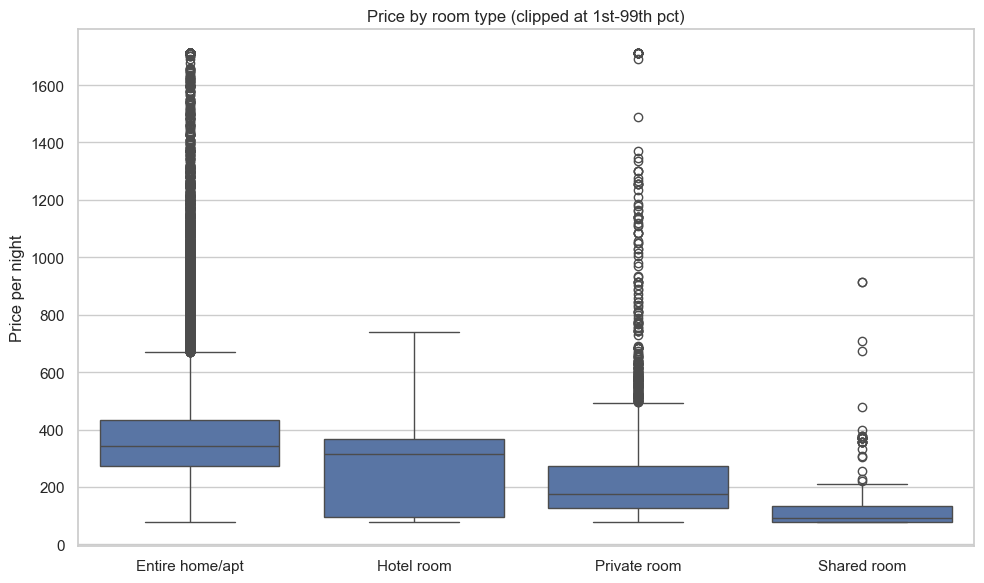

In [16]:
fig, ax = plt.subplots(figsize=(10, 6))
order = df_listings.groupby("room_type")["price_clean"].median().sort_values(ascending=False).index
sns.boxplot(
    data=df_listings.assign(price_trimmed=price_trimmed),
    x="room_type", y="price_trimmed", order=order, ax=ax,
)
ax.set_title("Price by room type (clipped at 1st-99th pct)")
ax.set_xlabel("")
ax.set_ylabel("Price per night")
plt.tight_layout()
plt.show()

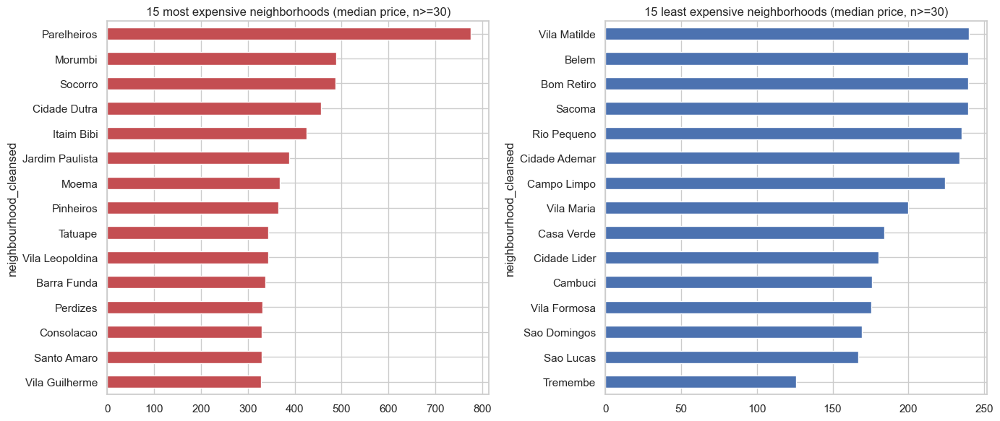

In [17]:
neigh_price = (
    df_listings.groupby("neighbourhood_cleansed")["price_clean"]
    .agg(median_price="median", n_listings="count")
    .query("n_listings >= 30")
    .sort_values("median_price", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
neigh_price.head(15)["median_price"].sort_values().plot(kind="barh", ax=axes[0], color="#C44E52")
axes[0].set_title("15 most expensive neighborhoods (median price, n>=30)")

neigh_price.tail(15)["median_price"].sort_values().plot(kind="barh", ax=axes[1], color="#4C72B0")
axes[1].set_title("15 least expensive neighborhoods (median price, n>=30)")

plt.tight_layout()
plt.show()

## 8. Spatial distribution

In [18]:
d = df_listings.dropna(subset=["latitude", "longitude", "price_clean"]).copy()
d["logprice"] = np.log1p(d["price_clean"])

fig = px.scatter_mapbox(
    d,
    lat="latitude", lon="longitude",
    color="logprice",
    color_continuous_scale="viridis",
    hover_data=["neighbourhood_cleansed", "price_clean"],
    zoom=10, height=700, opacity=0.6,
    mapbox_style="open-street-map",   # <-- the actual tile source, no token needed
)
fig.update_layout(margin=dict(l=0, r=0, t=30, b=0))
fig.show()

## Capacity, bedrooms, and price

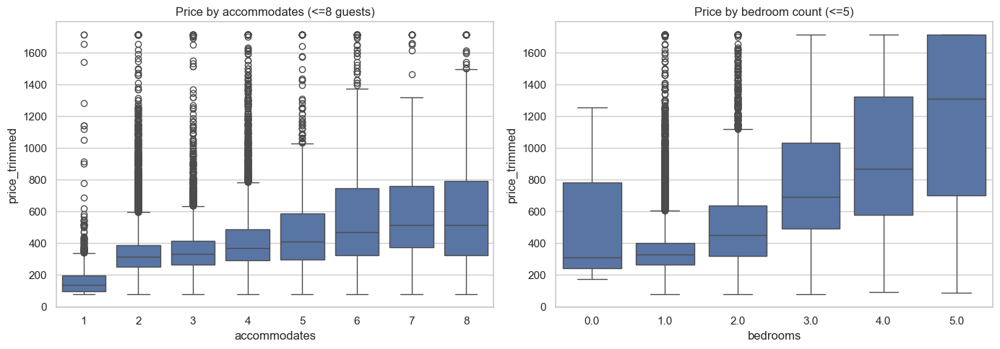

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df_listings.assign(price_trimmed=price_trimmed).query("accommodates <= 8"),
    x="accommodates", y="price_trimmed", ax=axes[0],
)
axes[0].set_title("Price by accommodates (<=8 guests)")

sns.boxplot(
    data=df_listings.assign(price_trimmed=price_trimmed).query("bedrooms <= 5"),
    x="bedrooms", y="price_trimmed", ax=axes[1],
)
axes[1].set_title("Price by bedroom count (<=5)")

plt.tight_layout()
plt.show()

## Availability & estimated revenue (from the listings snapshot)

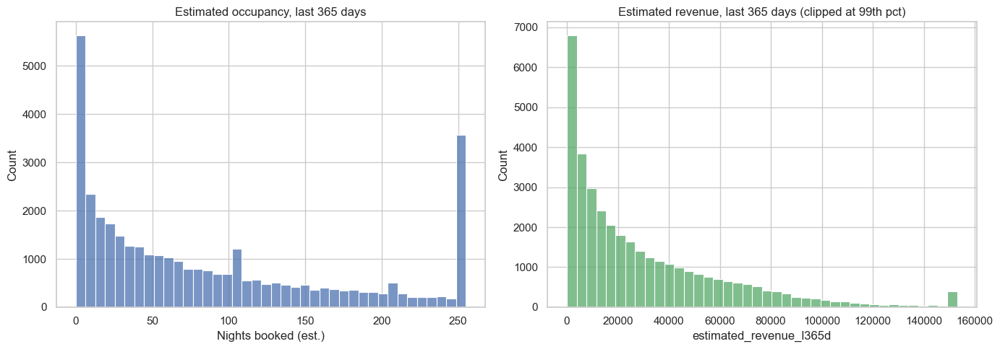

Correlation of price with occupancy/revenue proxies:
price_clean                  1.000000
estimated_occupancy_l365d   -0.099611
estimated_revenue_l365d      0.321400
availability_365             0.020372
Name: price_clean, dtype: float64


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_listings["estimated_occupancy_l365d"].dropna(), bins=40, ax=axes[0], color="#4C72B0")
axes[0].set_title("Estimated occupancy, last 365 days")
axes[0].set_xlabel("Nights booked (est.)")

rev_trimmed = df_listings["estimated_revenue_l365d"].clip(
    upper=df_listings["estimated_revenue_l365d"].quantile(0.99)
)
sns.histplot(rev_trimmed.dropna(), bins=40, ax=axes[1], color="#55A868")
axes[1].set_title("Estimated revenue, last 365 days (clipped at 99th pct)")

plt.tight_layout()
plt.show()

print("Correlation of price with occupancy/revenue proxies:")
print(
    df_listings[
        ["price_clean", "estimated_occupancy_l365d", "estimated_revenue_l365d", "availability_365"]
    ].corr()["price_clean"]
)

## Correlation matrix of key numeric features

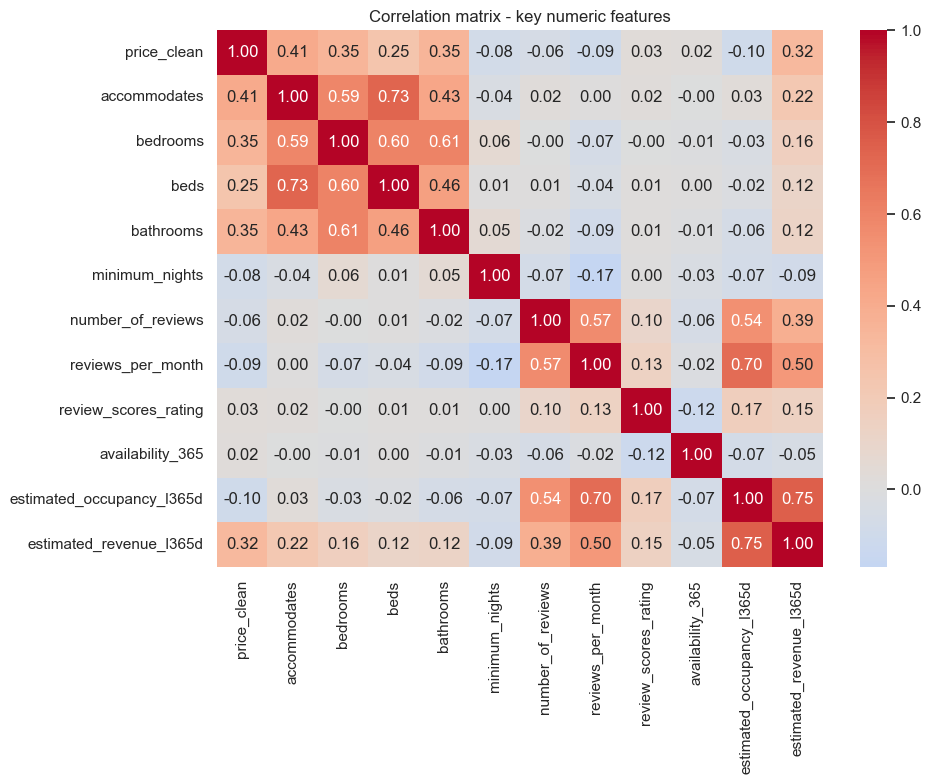

In [21]:
numeric_cols = [
    "price_clean", "accommodates", "bedrooms", "beds", "bathrooms",
    "minimum_nights", "number_of_reviews", "reviews_per_month",
    "review_scores_rating", "availability_365",
    "estimated_occupancy_l365d", "estimated_revenue_l365d",
]
corr = df_listings[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix - key numeric features")
plt.tight_layout()
plt.show()

## Reviews volume over time

reviews: (1577515, 2)  |  date range: 2011-04-19 to 2026-06-16


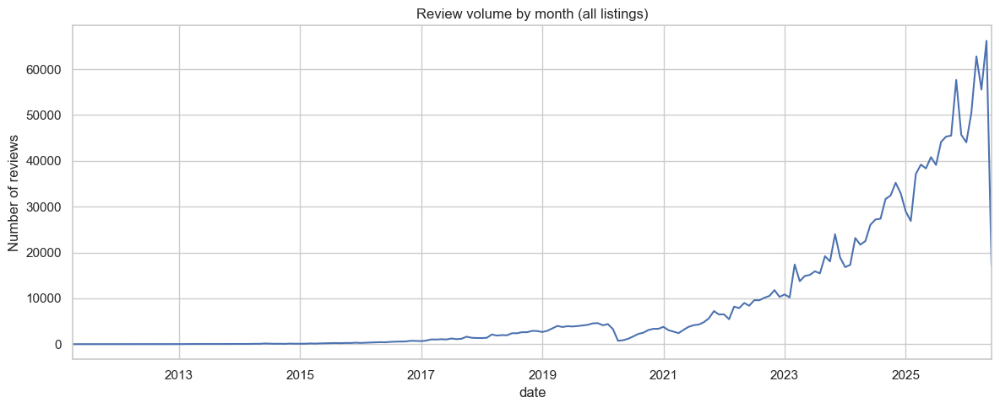

In [22]:
df_reviews = pd.read_csv(DATA_DIR / "reviews.csv", usecols=["listing_id", "date"], parse_dates=["date"])
print(f"reviews: {df_reviews.shape}  |  date range: {df_reviews['date'].min().date()} to {df_reviews['date'].max().date()}")

reviews_per_month = df_reviews["date"].dt.to_period("M").value_counts().sort_index()

fig, ax = plt.subplots(figsize=(12, 5))
reviews_per_month.plot(ax=ax, color="#4C72B0")
ax.set_title("Review volume by month (all listings)")
ax.set_ylabel("Number of reviews")
plt.tight_layout()
plt.show()

count    36604.000000
mean        43.096793
std         69.976108
min          1.000000
25%          6.000000
50%         19.000000
75%         52.000000
max       3314.000000
dtype: float64


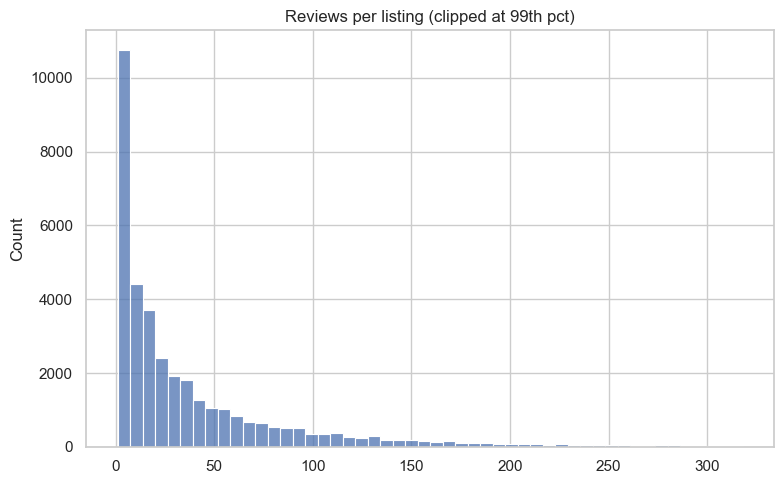

In [23]:
reviews_per_listing = df_reviews.groupby("listing_id").size()
print(reviews_per_listing.describe())

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(reviews_per_listing[reviews_per_listing <= reviews_per_listing.quantile(0.99)], bins=50, ax=ax)
ax.set_title("Reviews per listing (clipped at 99th pct)")
plt.tight_layout()
plt.show()

## Analysis by Neighbourhood

The central question of this section is not simply *which neighborhoods are most expensive*, but *where price, demand, and competition align to make a listing genuinely worth operating*. A high nightly price means little if the listing sits empty; a busy neighborhood means little if it's already saturated with professional hosts. The goal is to identify neighborhoods where an investor could enter and succeed, so we examine several dimensions in turn: price level and dispersion, demand, the price-demand relationship, competition and saturation, room-type economics, and finally a composite attractiveness ranking.

Throughout, we work at the `neighbourhood_cleansed` level and apply a minimum-listing threshold (`MIN_LISTINGS = 30`) so that comparisons aren't driven by a handful of listings in a thin neighborhood.

In [24]:
MIN_LISTINGS = 30

df_listings["is_professional_host"] = df_listings["calculated_host_listings_count"] > 1
df_listings["price_per_guest"] = df_listings["price_clean"] / df_listings["accommodates"].replace(0, np.nan)

neigh_stats = (
    df_listings.groupby("neighbourhood_cleansed")
    .agg(
        n_listings=("price_clean", "size"),
        median_price=("price_clean", "median"),
        mean_price=("price_clean", "mean"),
        p25_price=("price_clean", lambda s: s.quantile(0.25)),
        p75_price=("price_clean", lambda s: s.quantile(0.75)),
        median_reviews_per_month=("reviews_per_month", "median"),
        median_availability=("availability_365", "median"),
        median_estimated_revenue=("estimated_revenue_l365d", "median"),
        entire_home_share=("room_type", lambda s: (s == "Entire home/apt").mean()),
        professional_host_share=("is_professional_host", "mean"),
    )
    .assign(iqr_price=lambda d: d["p75_price"] - d["p25_price"])
    .query("n_listings >= @MIN_LISTINGS")
)

print(f"{len(neigh_stats)} of {df_listings['neighbourhood_cleansed'].nunique()} neighborhoods "
      f"have at least {MIN_LISTINGS} listings and are carried through this analysis.")
neigh_stats.head()

59 of 96 neighborhoods have at least 30 listings and are carried through this analysis.


,n_listings,median_price,mean_price,p25_price,p75_price,median_reviews_per_month,median_availability,median_estimated_revenue,entire_home_share,professional_host_share,iqr_price
neighbourhood_cleansed,,,,,,,,,,,
Agua Rasa,190,266.00,277.858105,210.0000,338.8750,1.625,350.5,27979.5,0.963158,0.921053,128.875
Alto De Pinheiros,221,320.00,422.884706,236.0000,415.0000,0.820,276.0,11856.0,0.778281,0.597285,179.000
Barra Funda,512,337.50,347.354473,277.9225,399.1025,2.000,284.5,27960.0,0.912109,0.728516,121.180
Bela Vista,2159,320.00,348.766202,262.0000,400.0000,1.380,290.0,20724.0,0.905049,0.760537,138.000
Belem,271,239.67,254.031550,160.0000,331.0000,1.630,344.0,18916.0,0.848708,0.771218,171.000


### Price level and dispersion

We begin with the median price per neighborhood, but the spread matters as much as the center. A neighborhood with a tightly clustered price (small interquartile range, IQR) is predictable to price into; one with a wide IQR signals that positioning, amenities, and presentation drive large price differences. High median price with manageable dispersion points to a market where a host can price with confidence rather than gamble.

                        median_price  iqr_price  n_listings
neighbourhood_cleansed                                     
Parelheiros                  776.000   745.2500          35
Morumbi                      489.400   427.4775         388
Socorro                      486.845   410.7500         108
Cidade Dutra                 456.750   409.4175         168
Itaim Bibi                   425.000   240.5500        3787
Jardim Paulista              388.000   158.5000        3029
Moema                        367.500   134.0000        2529
Pinheiros                    365.000   167.6225        2508
Tatuape                      344.000   121.0000         393
Vila Leopoldina              343.000   267.7500          57
Barra Funda                  337.500   121.1800         512
Perdizes                     331.000   118.7200        1729
Consolacao                   329.800   138.2700        1669
Santo Amaro                  329.000   131.5000        1615
Vila Guilherme               327.750   2

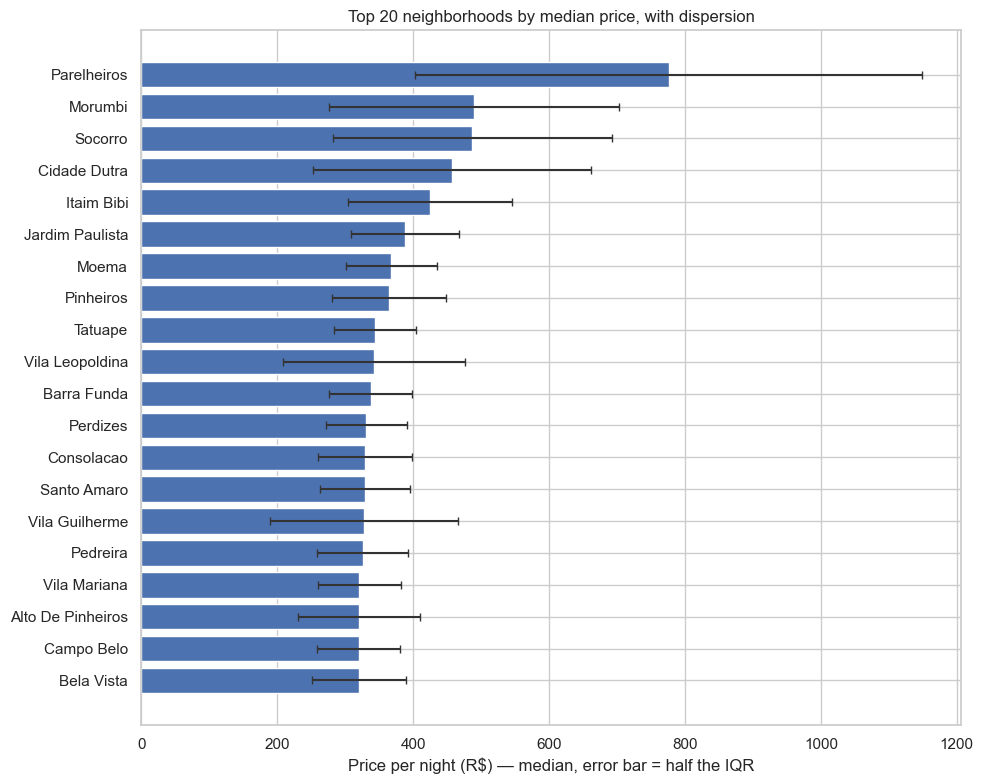

In [25]:
price_view = neigh_stats.sort_values("median_price", ascending=False)[
    ["median_price", "iqr_price", "n_listings"]
]
print(price_view.head(15))

top20_price = price_view.head(20).sort_values("median_price")

fig, ax = plt.subplots(figsize=(10, 8))
y_pos = np.arange(len(top20_price))
ax.barh(
    y_pos, top20_price["median_price"],
    xerr=top20_price["iqr_price"] / 2,
    color="#4C72B0", ecolor="#333333", capsize=3,
)
ax.set_yticks(y_pos)
ax.set_yticklabels(top20_price.index)
ax.set_xlabel("Price per night (R$) — median, error bar = half the IQR")
ax.set_title("Top 20 neighborhoods by median price, with dispersion")
plt.tight_layout()
plt.show()

### Demand

Because Inside Airbnb contains no real booking data, we rely on `reviews_per_month` as the least assumption-heavy demand proxy — a review only occurs after a stay, so it reflects genuine activity. We read this alongside `availability_365`: a neighborhood combining high review activity with low availability indicates listings that are consistently booked, the strongest possible demand signal available in this dataset.

                        median_reviews_per_month  median_availability  \
neighbourhood_cleansed                                                  
Se                                         2.530                310.0   
Santana                                    2.110                235.0   
Bras                                       2.030                317.0   
Barra Funda                                2.000                284.5   
Consolacao                                 1.820                276.0   
Republica                                  1.770                314.0   
Tucuruvi                                   1.730                308.5   
Belem                                      1.630                344.0   
Agua Rasa                                  1.625                350.5   
Vila Matilde                               1.600                343.0   
Vila Guilherme                             1.560                299.0   
Campo Belo                                 1.555   

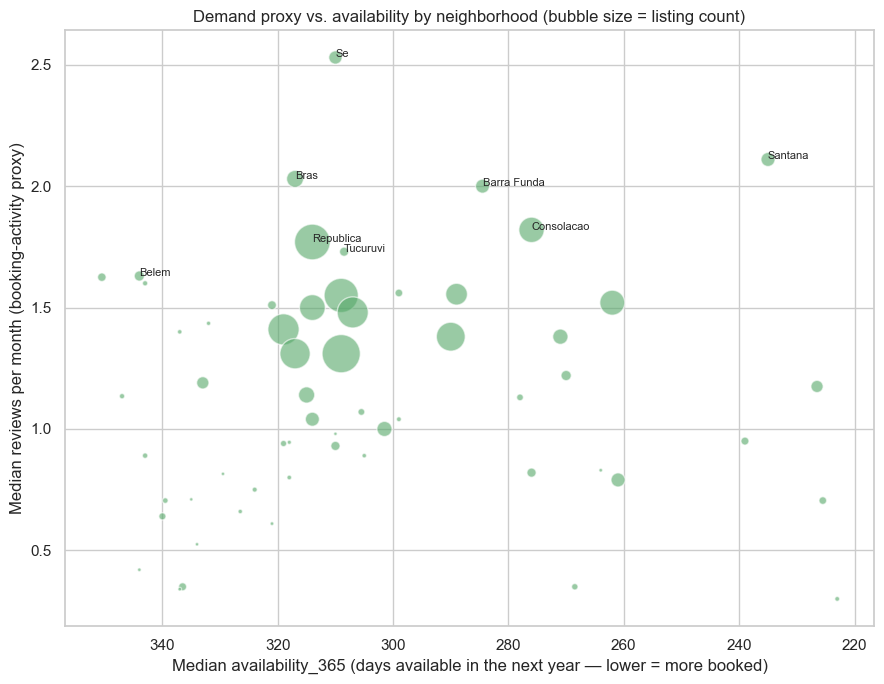

In [26]:
demand_view = neigh_stats.sort_values("median_reviews_per_month", ascending=False)[
    ["median_reviews_per_month", "median_availability", "n_listings"]
]
print(demand_view.head(15))

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(
    neigh_stats["median_availability"], neigh_stats["median_reviews_per_month"],
    s=neigh_stats["n_listings"] / 5, alpha=0.6, color="#55A868", edgecolor="white",
)
ax.set_xlabel("Median availability_365 (days available in the next year — lower = more booked)")
ax.set_ylabel("Median reviews per month (booking-activity proxy)")
ax.set_title("Demand proxy vs. availability by neighborhood (bubble size = listing count)")
ax.invert_xaxis()

standout = demand_view.sort_values(
    ["median_reviews_per_month", "median_availability"], ascending=[False, True]
).head(8)
for name, row in standout.iterrows():
    ax.annotate(name, (row["median_availability"], row["median_reviews_per_month"]), fontsize=8)

plt.tight_layout()
plt.show()

### The price–demand relationship

Crossing price against demand yields four neighborhood archetypes, split at the median of each metric across the qualifying neighborhoods. **Premium proven** markets sit high on both axes — desirable but crowded. The most interesting quadrant for a new investor is **underpriced opportunity**: *low price, high demand* — areas that are still underpriced yet reliably booked, where entry is affordable and occupancy is likely. **Aspirational / risky** (high price, low demand) areas are treated with caution, since their prices may be aspirational rather than realized. **Weak market** (low price, low demand) areas are set aside. This quadrant analysis is the analytical heart of the section, because it directly maps neighborhoods onto investment desirability.

quadrant
Premium proven             19
Weak market                18
Underpriced opportunity    11
Aspirational / risky       11
Name: count, dtype: int64


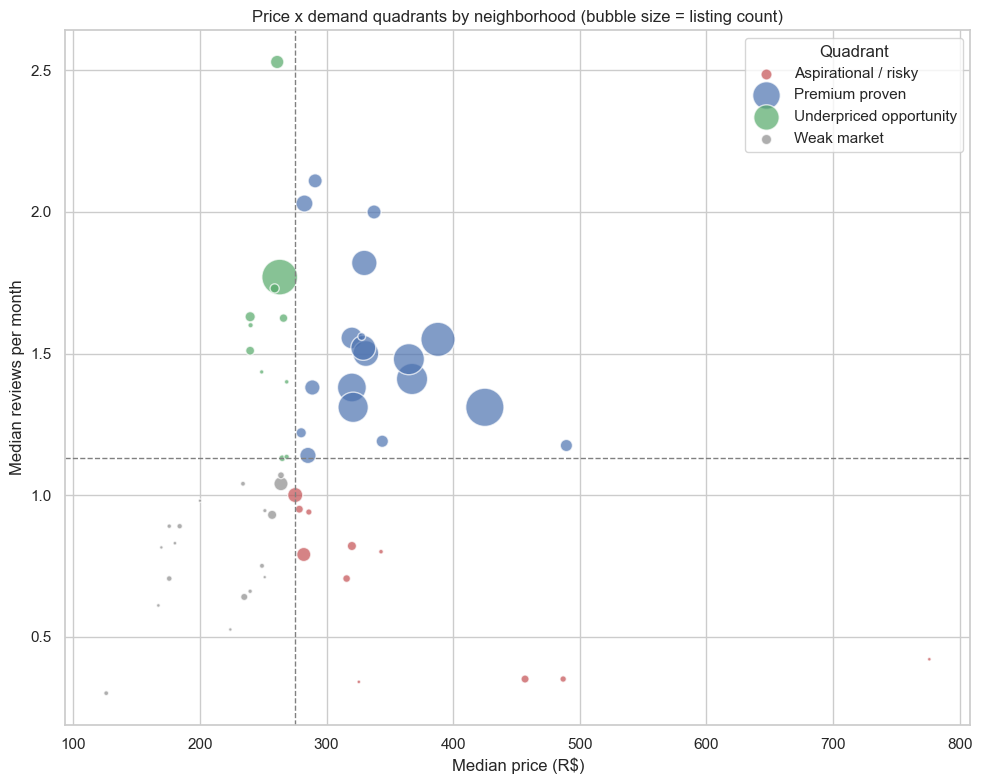


11 neighborhoods in the 'underpriced opportunity' quadrant:
                        median_price  median_reviews_per_month  n_listings
neighbourhood_cleansed                                                    
Se                            261.00                     2.530         463
Republica                     263.00                     1.770        3303
Tucuruvi                      259.00                     1.730         218
Belem                         239.67                     1.630         271
Agua Rasa                     266.00                     1.625         190
Vila Matilde                  240.00                     1.600          73
Bom Retiro                    239.65                     1.510         205
Pari                          248.75                     1.435          50
Jardim Sao Luis               268.50                     1.400          55
Penha                         268.50                     1.135          74
Cursino                       265.00   

In [27]:
price_cut = neigh_stats["median_price"].median()
demand_cut = neigh_stats["median_reviews_per_month"].median()


def quadrant(row):
    high_price = row["median_price"] >= price_cut
    high_demand = row["median_reviews_per_month"] >= demand_cut
    if high_price and high_demand:
        return "Premium proven"
    if not high_price and high_demand:
        return "Underpriced opportunity"
    if high_price and not high_demand:
        return "Aspirational / risky"
    return "Weak market"


neigh_stats["quadrant"] = neigh_stats.apply(quadrant, axis=1)
print(neigh_stats["quadrant"].value_counts())

palette = {
    "Premium proven": "#4C72B0",
    "Underpriced opportunity": "#55A868",
    "Aspirational / risky": "#C44E52",
    "Weak market": "#8C8C8C",
}

fig, ax = plt.subplots(figsize=(10, 8))
for label, group in neigh_stats.groupby("quadrant"):
    ax.scatter(
        group["median_price"], group["median_reviews_per_month"],
        s=group["n_listings"] / 5, alpha=0.7, label=label,
        color=palette[label], edgecolor="white",
    )
ax.axvline(price_cut, color="gray", linestyle="--", linewidth=1)
ax.axhline(demand_cut, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Median price (R$)")
ax.set_ylabel("Median reviews per month")
ax.set_title("Price x demand quadrants by neighborhood (bubble size = listing count)")
ax.legend(title="Quadrant")
plt.tight_layout()
plt.show()

opportunity = neigh_stats.query("quadrant == 'Underpriced opportunity'").sort_values(
    "median_reviews_per_month", ascending=False
)
print(f"\n{len(opportunity)} neighborhoods in the 'underpriced opportunity' quadrant:")
print(opportunity[["median_price", "median_reviews_per_month", "n_listings"]])

### Competition and saturation

Demand must be weighed against supply. We measure the number of active listings per neighborhood, the share that are entire homes versus private rooms, and the proportion operated by professional multi-listing hosts (`calculated_host_listings_count > 1`, i.e. a host with more than one active listing in this snapshot). A neighborhood with strong demand but relatively few listings — and a lower share of professional operators — is under-served, and therefore easier for a newcomer to enter and win. Conversely, a saturated market dominated by professionals raises the bar for any new entrant.

Competition snapshot, all qualifying neighborhoods (sorted by professional-host share):
                        n_listings  entire_home_share  professional_host_share
neighbourhood_cleansed                                                        
Parelheiros                     35           0.942857                 0.200000
Cambuci                         54           0.685185                 0.370370
Jardim Sao Luis                 55           0.854545                 0.454545
Vila Matilde                    73           0.917808                 0.465753
Vila Andrade                   154           0.844156                 0.487013
Sao Lucas                       36           0.722222                 0.500000
Sacoma                          52           0.673077                 0.500000
Campo Limpo                     32           0.843750                 0.500000
Pirituba                        31           0.677419                 0.516129
Mooca                          103         

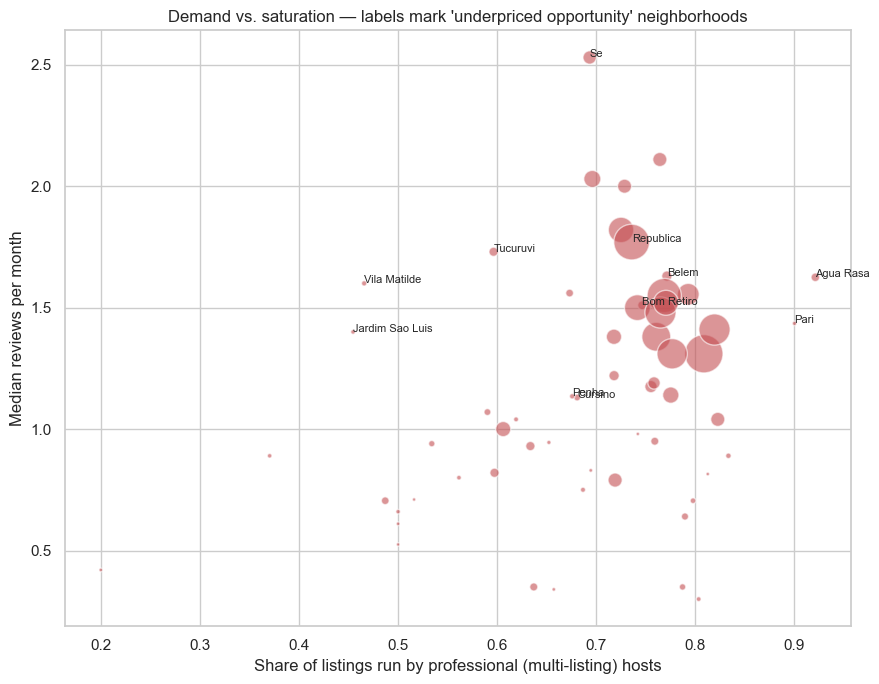

In [28]:
print("Competition snapshot, all qualifying neighborhoods (sorted by professional-host share):")
print(
    neigh_stats.sort_values("professional_host_share")
    [["n_listings", "entire_home_share", "professional_host_share"]]
    .head(15)
)

print("\nCompetition snapshot restricted to the 'underpriced opportunity' quadrant:")
print(
    opportunity.sort_values("professional_host_share")
    [["median_price", "median_reviews_per_month", "n_listings", "professional_host_share", "entire_home_share"]]
)

fig, ax = plt.subplots(figsize=(9, 7))
ax.scatter(
    neigh_stats["professional_host_share"], neigh_stats["median_reviews_per_month"],
    s=neigh_stats["n_listings"] / 5, alpha=0.6, color="#C44E52", edgecolor="white",
)
for name, row in opportunity.iterrows():
    ax.annotate(name, (row["professional_host_share"], row["median_reviews_per_month"]), fontsize=8)
ax.set_xlabel("Share of listings run by professional (multi-listing) hosts")
ax.set_ylabel("Median reviews per month")
ax.set_title("Demand vs. saturation — labels mark 'underpriced opportunity' neighborhoods")
plt.tight_layout()
plt.show()

### Room-type economics

The dominant room type shapes the investment strategy itself. Where entire homes dominate, the play is a dedicated buy-to-let unit; where private rooms prevail, the market leans toward residents renting spare space. Comparing price-per-guest across room types within each opportunity neighborhood clarifies which strategy the local market actually rewards.

In [29]:
opportunity_names = opportunity.index.tolist()

room_econ = (
    df_listings[df_listings["neighbourhood_cleansed"].isin(opportunity_names)]
    .groupby(["neighbourhood_cleansed", "room_type"])["price_per_guest"]
    .agg(median_price_per_guest="median", n="size")
    .query("n >= 5")
    .sort_index()
)
print(room_econ)

dominant_room_type = (
    df_listings[df_listings["neighbourhood_cleansed"].isin(opportunity_names)]
    .groupby("neighbourhood_cleansed")["room_type"]
    .agg(lambda s: s.value_counts().idxmax())
)
print("\nDominant room type per opportunity neighborhood:")
print(dominant_room_type)

                                        median_price_per_guest     n
neighbourhood_cleansed room_type                                    
Agua Rasa              Entire home/apt              106.000000   183
                       Private room                  88.000000     7
Belem                  Entire home/apt               86.150000   230
                       Private room                  88.500000    40
Bom Retiro             Entire home/apt               98.000000   171
                       Private room                 103.000000    21
                       Shared room                   10.333333    13
Cursino                Entire home/apt              117.333333    97
                       Private room                  82.267500    22
Jardim Sao Luis        Entire home/apt               91.295000    47
                       Private room                 102.710000     8
Pari                   Entire home/apt               80.418333    32
                       Private roo

### A composite attractiveness ranking

Finally, we synthesize these dimensions into a single ranked score, rewarding demand and revenue potential while penalizing saturation. Each component is z-scored across the qualifying neighborhoods so they're comparable despite different units, then combined with explicit weights:

```
attractiveness_score = 0.40 * z(median_reviews_per_month)      # demand
                      + 0.35 * z(median_estimated_revenue)     # revenue potential
                      - 0.25 * z(professional_host_share)      # saturation penalty
```

The weighting is a deliberate analytical choice — demand and revenue potential carry the most weight, competition acts as a discount — and stating those weights explicitly keeps the ranking transparent and defensible rather than arbitrary. The resulting shortlist of top neighborhoods becomes the bridge to the next phase of the project: these are precisely the areas where the crime and tourism datasets (the São Paulo risk source and Google Places / TripAdvisor) will add the most value, refining a price-and-demand ranking into a fuller picture of where an Airbnb investment makes sense.

                        attractiveness_score  median_price  \
neighbourhood_cleansed                                       
Se                                  1.995903       261.000   
Santana                             1.317057       291.000   
Bras                                1.204823       282.525   
Barra Funda                         1.192393       337.500   
Tucuruvi                            1.025905       259.000   
Jardim Sao Luis                     0.975784       268.500   
Consolacao                          0.935170       329.800   
Vila Matilde                        0.840126       240.000   
Vila Guilherme                      0.757250       327.750   
Republica                           0.707477       263.000   
Jardim Paulista                     0.601581       388.000   
Agua Rasa                           0.522421       266.000   
Morumbi                             0.470011       489.400   
Pinheiros                           0.435293       365.000   
Bom Reti

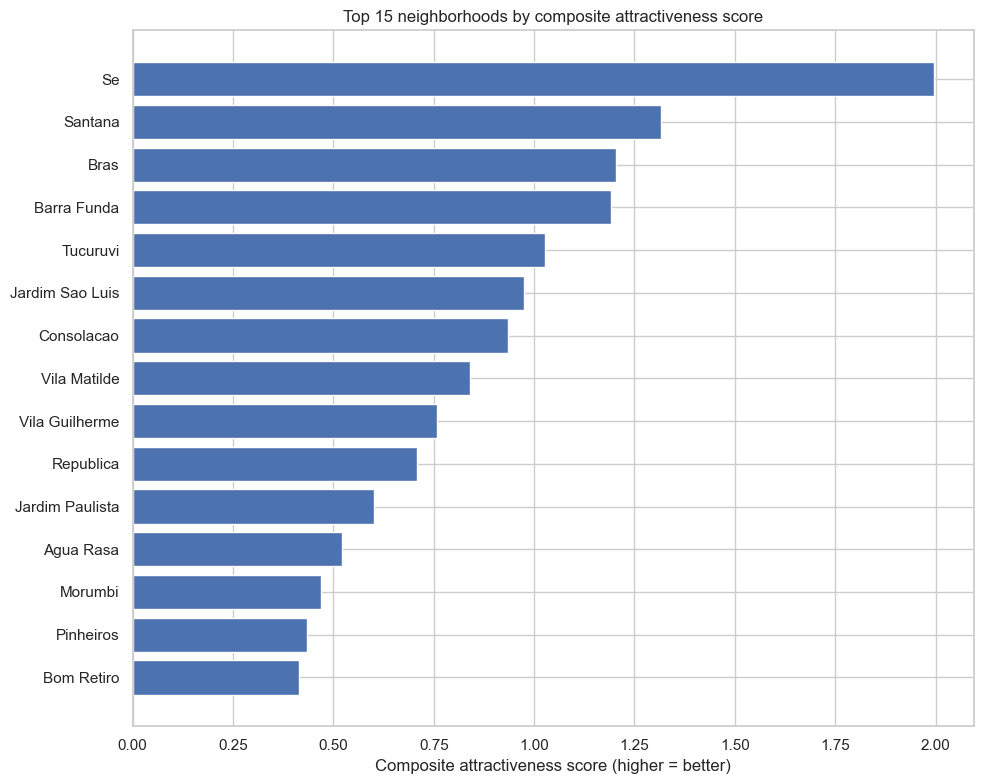

In [30]:
def zscore(s: pd.Series) -> pd.Series:
    return (s - s.mean()) / s.std()


W_DEMAND, W_REVENUE, W_SATURATION = 0.40, 0.35, 0.25

neigh_stats["z_demand"] = zscore(neigh_stats["median_reviews_per_month"])
neigh_stats["z_revenue"] = zscore(neigh_stats["median_estimated_revenue"])
neigh_stats["z_saturation"] = zscore(neigh_stats["professional_host_share"])

neigh_stats["attractiveness_score"] = (
    W_DEMAND * neigh_stats["z_demand"]
    + W_REVENUE * neigh_stats["z_revenue"]
    - W_SATURATION * neigh_stats["z_saturation"]
)

ranked = neigh_stats.sort_values("attractiveness_score", ascending=False)
top15 = ranked.head(15)
print(
    top15[[
        "attractiveness_score", "median_price", "median_reviews_per_month",
        "median_estimated_revenue", "professional_host_share", "n_listings", "quadrant",
    ]]
)

fig, ax = plt.subplots(figsize=(10, 8))
order = top15.index[::-1]
ax.barh(order, top15.loc[order, "attractiveness_score"], color="#4C72B0")
ax.set_xlabel("Composite attractiveness score (higher = better)")
ax.set_title("Top 15 neighborhoods by composite attractiveness score")
plt.tight_layout()
plt.show()

### Caveats

Two caveats are worth stating explicitly. First, all demand figures here are proxies, not measured occupancy, and should be read comparatively (neighborhood A busier than B) rather than as literal booking rates — `reviews_per_month` and `estimated_revenue_l365d` are Inside-Airbnb-modeled estimates, not verified transactions (see `obsidian-vault/02 - Data Sources/Inside Airbnb.md`). Second, neighborhoods with few listings produce noisy statistics, so the `MIN_LISTINGS = 30` threshold is applied throughout to keep comparisons meaningful.

In [31]:
top3 = ranked.head(3)
for name, row in top3.iterrows():
    print(f"{name}")
    print(f"  score={row['attractiveness_score']:.2f}  quadrant={row['quadrant']}")
    print(f"  median_price=R$ {row['median_price']:.0f}  median_reviews_per_month={row['median_reviews_per_month']:.2f}")
    print(f"  median_estimated_revenue=R$ {row['median_estimated_revenue']:.0f}  "
          f"professional_host_share={row['professional_host_share']:.1%}  n_listings={row['n_listings']:.0f}")
    print()

Se
  score=2.00  quadrant=Underpriced opportunity
  median_price=R$ 261  median_reviews_per_month=2.53
  median_estimated_revenue=R$ 34752  professional_host_share=69.3%  n_listings=463

Santana
  score=1.32  quadrant=Premium proven
  median_price=R$ 291  median_reviews_per_month=2.11
  median_estimated_revenue=R$ 30240  professional_host_share=76.4%  n_listings=513

Bras
  score=1.20  quadrant=Premium proven
  median_price=R$ 283  median_reviews_per_month=2.03
  median_estimated_revenue=R$ 26298  professional_host_share=69.6%  n_listings=750



### Top neighborhoods

The composite ranking resolves into three standouts:

- **Se** (score 2.00) is the strongest result and the only top-3 neighborhood in the "underpriced opportunity" quadrant: a modest median price (R$ 261) paired with the highest demand signal in the top tier (2.53 median reviews/month) and the highest revenue potential of the three (R$ 34,752 median estimated annual revenue), across 463 qualifying listings. Its professional-host share (69.3%) is real but not extreme, leaving room for a new entrant.
- **Santana** (score 1.32) is a "premium proven" market — a higher median price (R$ 291) with solid demand (2.11 reviews/month), but the most professionalized of the three (76.4% multi-listing hosts), meaning a newcomer competes directly with established operators rather than finding open space.
- **Bras** (score 1.20) rounds out the shortlist, also "premium proven," with the largest supply base (750 listings) and a comparable professional-host share (69.6%) to Se, but lower demand and revenue — a validated but less differentiated market.

Taken together, **Se is the clearest near-term opportunity** — underpriced relative to its demand and revenue — while Santana and Bras are safer, already-validated markets better suited to an entrant with the capital and positioning to compete against incumbent professional hosts. All three carry forward as priority candidates once the crime-risk and tourist-appeal data sources are integrated.

## Save the cleaned DF

In [32]:
df_listings.to_csv("listings_clean.csv", index=False)